# Inteligencia de enjambre y evolución diferencial: PSO y DE

**Bloque 03 · Métodos poblacionales · Notebook 11**

Navegación: [← 10 BRKGA, meméticos y scatter search](10-brkga-memeticos-scatter-search.ipynb) · [12 Optimización multiobjetivo →](../04-topicos-avanzados/12-optimizacion-multiobjetivo.ipynb) · Relacionado: [09 Algoritmos genéticos](09-algoritmos-geneticos.ipynb) · [08 Colonia de hormigas](../02-metodos-con-memoria/08-colonia-de-hormigas.ipynb)

## Tabla de contenido
1. Funciones de prueba: Rastrigin, Ackley, Rosenbrock
2. Optimización por enjambre de partículas (PSO): ecuaciones, topologías, constricción
3. Análisis de estabilidad (cualitativo y verificado numéricamente)
4. Evolución diferencial (DE): `rand/1/bin`, `best/1/bin`, parámetros $F$ y $CR$
5. Visualización: instantáneas del enjambre sobre curvas de nivel
6. Un AG de codificación real como tercer competidor
7. Comparación PSO vs. DE vs. GA en 10D y 30D (varias semillas)
8. Sensibilidad a parámetros
9. PSO discreto / de permutaciones (vector diferencial de swaps) para TSP
10. Resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Vas a aprender a**
- implementar **PSO** (inercia, factor de constricción, topologías *gbest*/*lbest*) y **DE** (`rand/1/bin`, `best/1/bin`) desde cero, vectorizados en NumPy;
- razonar sobre la **estabilidad** de la dinámica del enjambre con el polinomio característico y verificarla numéricamente;
- visualizar el comportamiento de un enjambre sobre **curvas de nivel** con instantáneas por iteración;
- comparar PSO, DE y un AG real con curvas de convergencia y tablas **media $\pm$ desviación** sobre varias semillas;
- adaptar PSO a **permutaciones** con una noción de "vector diferencial" basada en secuencias de swaps.

**Prerrequisitos**: [notebook 09](09-algoritmos-geneticos.ipynb) (AG, selección, cruce) y nociones básicas de álgebra lineal (valores propios).

## 1. Optimización continua y funciones de prueba

### Objetivo
Resolver $\min_{x\in[l,u]^D}f(x)$ sin gradientes (caja negra). Las funciones de prueba clásicas, con óptimo global $f^{*}=0$:

| Función | Fórmula | Dominio | Óptimo | Dificultad |
|---|---|---|---|---|
| Rastrigin | $10D+\sum_i\big(x_i^2-10\cos(2\pi x_i)\big)$ | $[-5.12,5.12]^D$ | $x=\mathbf 0$ | multimodal masiva ($\sim10^D$ mínimos locales), separable |
| Ackley | $-20e^{-0.2\sqrt{\frac1D\sum x_i^2}}-e^{\frac1D\sum\cos(2\pi x_i)}+20+e$ | $[-32.768,32.768]^D$ | $x=\mathbf 0$ | meseta exterior casi plana + agujero estrecho, no separable |
| Rosenbrock | $\sum_{i=1}^{D-1}\big[100(x_{i+1}-x_i^2)^2+(1-x_i)^2\big]$ | $[-2.048,2.048]^D$ | $x=\mathbf 1$ | valle curvo estrecho (unimodal para $D\le3$, con mínimo local extra para $D\ge4$), no separable |

Las implementaciones reciben una matriz $(N,D)$ y devuelven $N$ valores (vectorización por población).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import math, time, multiprocessing as mp
from itertools import combinations

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11})
np.random.seed(0)
rng0 = np.random.default_rng(2024)
CTX = mp.get_context("fork")
def pmap(fn, tasks, procs=10):
    with CTX.Pool(min(procs, len(tasks))) as pool:
        return pool.map(fn, tasks, chunksize=1)

# ---------------- Funciones de prueba (vectorizadas: X de forma (N, D) -> (N,)) ----------------
def rastrigin(X):
    X = np.atleast_2d(X); return 10 * X.shape[1] + np.sum(X ** 2 - 10 * np.cos(2 * np.pi * X), axis=1)

def ackley(X):
    X = np.atleast_2d(X); D = X.shape[1]
    return (-20 * np.exp(-0.2 * np.sqrt(np.sum(X ** 2, axis=1) / D)) - np.exp(np.sum(np.cos(2 * np.pi * X), axis=1) / D) + 20 + np.e)

def rosenbrock(X):
    X = np.atleast_2d(X); return np.sum(100 * (X[:, 1:] - X[:, :-1] ** 2) ** 2 + (1 - X[:, :-1]) ** 2, axis=1)

FUNCS = {"Rastrigin": (rastrigin, -5.12, 5.12, 0.0), "Ackley": (ackley, -32.768, 32.768, 0.0), "Rosenbrock": (rosenbrock, -2.048, 2.048, 0.0)}

# verificación de óptimos
for nombre, (f, lo, hi, fstar) in FUNCS.items():
    D = 7; x_opt = np.ones((1, D)) if nombre == "Rosenbrock" else np.zeros((1, D))
    assert abs(f(x_opt)[0] - fstar) < 1e-12
    print(f"{nombre:11s} f(óptimo, D=7) = {f(x_opt)[0]:.2e}; valor medio en puntos aleatorios del dominio: {f(rng0.uniform(lo, hi, (2000, D))).mean():.2f}")

Rastrigin   f(óptimo, D=7) = 0.00e+00; valor medio en puntos aleatorios del dominio: 130.35
Ackley      f(óptimo, D=7) = 4.44e-16; valor medio en puntos aleatorios del dominio: 21.06
Rosenbrock  f(óptimo, D=7) = 0.00e+00; valor medio en puntos aleatorios del dominio: 2896.41


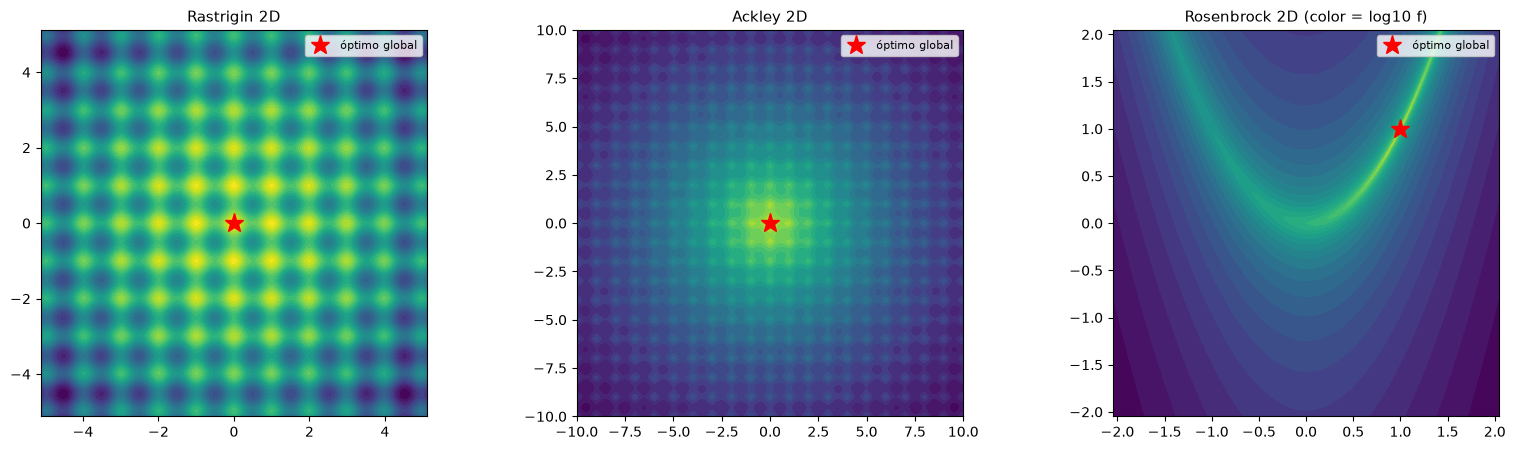

In [2]:
# Curvas de nivel de las tres funciones en 2D
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
VIEW = {"Rastrigin": (-5.12, 5.12), "Ackley": (-10, 10), "Rosenbrock": (-2.048, 2.048)}
def contornos(ax, nombre, n=300):
    f = FUNCS[nombre][0]; a, b = VIEW[nombre]
    g = np.linspace(a, b, n); XX, YY = np.meshgrid(g, g)
    Z = f(np.c_[XX.ravel(), YY.ravel()]).reshape(XX.shape)
    ax.contourf(XX, YY, np.log10(Z + 1e-2) if nombre == "Rosenbrock" else Z, levels=30, cmap="viridis_r"); ax.set_aspect("equal"); ax.grid(False)
for ax, nombre in zip(axs, FUNCS):
    contornos(ax, nombre); ax.set_title(f"{nombre} 2D" + (" (color = log10 f)" if nombre == "Rosenbrock" else ""))
    ax.plot(*((1, 1) if nombre == "Rosenbrock" else (0, 0)), "r*", ms=14, label="óptimo global"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

## 2. Optimización por enjambre de partículas (PSO)

### Intuición
Una bandada de aves busca comida: cada ave recuerda el mejor sitio que **ella** encontró (memoria cognitiva) y sabe cuál es el mejor sitio que encontró **su vecindario** (influencia social); se mueve con cierta inercia y una atracción hacia ambos. (Kennedy & Eberhart, 1995.) Es un algoritmo poblacional con **memoria individual** y **sin selección**: nadie muere, todos se mueven.

### Formulación
Partícula $i$ con posición $x_i\in\mathbb R^D$, velocidad $v_i$, mejor posición personal $p_i$ y mejor posición del vecindario $g_i$:
$$v_i^{t+1}=w\,v_i^{t}+c_1\,r_1\odot(p_i-x_i^t)+c_2\,r_2\odot(g_i-x_i^t),\qquad x_i^{t+1}=x_i^t+v_i^{t+1}$$
con $r_1,r_2\sim U(0,1)^D$ (muestreados por dimensión), $w$ la **inercia**, $c_1$ el coeficiente **cognitivo** y $c_2$ el **social**. Por qué cada término:
- $w v$: conserva la dirección (exploración; $w$ alto → trayectorias largas);
- $c_1r_1(p-x)$: vuelve al mejor sitio propio (diversidad: cada partícula tiene su propio atractor);
- $c_2r_2(g-x)$: acercarse al líder (convergencia).

**Topologías.** *gbest*: $g_i$ es el mejor de todo el enjambre (convergencia rápida, riesgo de prematura). *lbest* en anillo: $g_i$ es el mejor entre $i-1,i,i+1$ (la información se difunde lentamente; más exploración; mejor en funciones multimodales).

**Factor de constricción** (Clerc & Kennedy, 2002): con $\varphi=c_1+c_2>4$ y
$$\chi=\frac{2}{\left|2-\varphi-\sqrt{\varphi^2-4\varphi}\right|},\qquad v^{t+1}=\chi\big(v^t+c_1r_1(p-x)+c_2r_2(g-x)\big)$$
(con $c_1=c_2=2.05$ resulta $\chi\approx0.7298$, equivalente a $w=0.7298$ y $c_{1,2}=1.496$). Aquí es el tratamiento estándar para garantizar convergencia.

### Pseudocódigo
```
inicializar x_i ~ U[l,u]^D, v_i pequeñas ; p_i <- x_i ; f_i <- f(x_i)
repetir hasta agotar evaluaciones:
    para cada partícula i:
        g_i <- mejor p_j del vecindario de i
        v_i <- w*v_i + c1*r1*(p_i - x_i) + c2*r2*(g_i - x_i)       (o con chi)
        x_i <- x_i + v_i ; recortar a [l,u] (y anular la velocidad en las dimensiones recortadas)
        si f(x_i) < f(p_i): p_i <- x_i
devolver el mejor p_i
```

In [3]:
def pso(f, lo, hi, D, N=30, evals=20000, w=0.7298, c1=1.49618, c2=1.49618, topo="gbest", chi=False, w_final=None,
        vmax_frac=0.5, seed=0, snaps=None):
    # PSO vectorizado. f(X:(N,D))->(N,). topo: 'gbest' | 'ring' (lbest con vecindad i-1,i,i+1).
    # chi=True usa constricción de Clerc-Kennedy (requiere c1+c2>4). w_final: si se da, la inercia decrece linealmente de w a w_final.
    rng = np.random.default_rng(seed); R = hi - lo
    X = lo + R * rng.random((N, D)); V = 0.2 * R * (rng.random((N, D)) - 0.5)
    fx = f(X); used = N; P, pf = X.copy(), fx.copy()
    if chi:
        phi = c1 + c2; assert phi > 4, "la constricción requiere c1+c2>4"
        k = 2 / abs(2 - phi - math.sqrt(phi ** 2 - 4 * phi))
    iters = max(1, (evals - N) // N); idx3 = (np.arange(N)[None, :] + np.array([-1, 0, 1])[:, None]) % N
    ev, best = [used], [pf.min()]; saved = {}
    if snaps is not None and 0 in snaps: saved[0] = (X.copy(), P[pf.argmin()].copy())
    for t in range(1, iters + 1):
        if topo == "gbest": G = np.broadcast_to(P[pf.argmin()], (N, D))
        else:                                              # anillo: mejor pbest entre los vecinos i-1, i, i+1
            lead = idx3[np.argmin(pf[idx3], axis=0), np.arange(N)]; G = P[lead]
        r1, r2 = rng.random((N, D)), rng.random((N, D))
        if chi: V = k * (V + c1 * r1 * (P - X) + c2 * r2 * (G - X))
        else:
            wt = w if w_final is None else w + (w_final - w) * t / iters
            V = wt * V + c1 * r1 * (P - X) + c2 * r2 * (G - X)
        V = np.clip(V, -vmax_frac * R, vmax_frac * R)
        X = X + V
        fuera = (X < lo) | (X > hi); X = np.clip(X, lo, hi); V = np.where(fuera, 0.0, V)   # absorción en la frontera
        fx = f(X); used += N
        mej = fx < pf; P[mej], pf[mej] = X[mej], fx[mej]
        ev.append(used); best.append(pf.min())
        if snaps is not None and t in snaps: saved[t] = (X.copy(), P[pf.argmin()].copy())
    i = pf.argmin()
    return dict(ev=np.array(ev), best=np.array(best), x=P[i].copy(), f=pf[i], snaps=saved)

r = pso(rastrigin, -5.12, 5.12, 10, evals=20000, seed=0, topo="ring")
print("PSO anillo en Rastrigin 10D con 20000 evaluaciones -> f =", round(r["f"], 3))

PSO anillo en Rastrigin 10D con 20000 evaluaciones -> f = 5.97


### Validación de la implementación
Verificamos: (i) las posiciones respetan la caja; (ii) el mejor global es monótono no creciente; (iii) la **vecindad en anillo** selecciona realmente al mejor de $\{i-1,i,i+1\}$; (iv) con $\chi$ se obtiene el valor teórico 0.7298; (v) la esfera se resuelve con alta precisión.

In [4]:
sphere = lambda X: np.sum(np.atleast_2d(X) ** 2, axis=1)
r = pso(sphere, -5, 5, 10, N=30, evals=30000, seed=1, snaps=[0, 5, 50])
assert np.all(np.diff(r["best"]) <= 1e-15)
assert all(np.all(S >= -5) and np.all(S <= 5) for S, _ in r["snaps"].values())
print("(i)-(ii) posiciones dentro de la caja y mejor global monótono: OK.")
# (iii) anillo: comprobación independiente de la regla de vecindad
N = 12; pf = rng0.random(N); idx3 = (np.arange(N)[None, :] + np.array([-1, 0, 1])[:, None]) % N
lead = idx3[np.argmin(pf[idx3], axis=0), np.arange(N)]
for i in range(N):
    vec = [(i - 1) % N, i, (i + 1) % N]; assert lead[i] == vec[int(np.argmin(pf[vec]))]
print("(iii) vecindad en anillo verificada contra la definición.")
phi = 4.1; k = 2 / abs(2 - phi - math.sqrt(phi ** 2 - 4 * phi)); print(f"(iv) chi(phi=4.1) = {k:.4f} (valor teórico 0.7298)")
r = pso(sphere, -5, 5, 10, evals=30000, chi=True, c1=2.05, c2=2.05, seed=2)
print(f"(v) PSO con constricción en la esfera 10D: f final = {r['f']:.2e}")

(i)-(ii) posiciones dentro de la caja y mejor global monótono: OK.
(iii) vecindad en anillo verificada contra la definición.
(iv) chi(phi=4.1) = 0.7298 (valor teórico 0.7298)
(v) PSO con constricción en la esfera 10D: f final = 3.84e-48


## 3. Análisis de estabilidad (cualitativo)

Consideremos una partícula **aislada** en una dimensión, con $p=g$ fijos (estancamiento). Sea $\varphi=c_1r_1+c_2r_2$ el coeficiente de atracción total en un paso. Entonces
$$x_{t+1}=(1+w-\varphi)\,x_t-w\,x_{t-1}+\varphi\,p,$$
una recurrencia lineal cuyo punto fijo es $x=p$ y cuyo polinomio característico es $\lambda^2-(1+w-\varphi)\lambda+w=0$. La trayectoria converge si y solo si ambas raíces cumplen $|\lambda|<1$, es decir, exactamente en el triángulo
$$|w|<1,\qquad 0<\varphi<2(1+w).$$
Dos lecturas de $\varphi$:
- **Caso "determinista" de Clerc & Kennedy**: $r_1=r_2=1$, $\varphi=c_1+c_2$ (peor caso). Es el análisis que lleva al factor de constricción y el que graficamos abajo.
- **Caso estocástico**: $\varphi$ es aleatoria con media $\bar\varphi=(c_1+c_2)/2$. La media de $x_t$ converge si $\bar\varphi<2(1+w)$, es decir $c_1+c_2<4(1+w)$.

Interpretación: $w\ge1$ → la inercia nunca se amortigua; $\varphi$ muy grande → sobre-corrección en cada paso; $\varphi$ pequeña → convergencia lenta. Con raíces **complejas** ($(1+w-\varphi)^2<4w$) la trayectoria **oscila** alrededor de $p$ (típico de PSO); con raíces reales converge monótonamente.

**Convergencia en media vs. en varianza.** Como $\varphi$ es aleatoria, no basta con que la media converja: hay que mirar el **segundo momento** $E[x_t^2]$. Bajo estancamiento con $r_1,r_2\sim U(0,1)$, Poli (2009) obtuvo que $E[x_t^2]\to0$ si y solo si
$$c_1+c_2<\frac{24\,(1-w^2)}{7-5w}\qquad(|w|<1),$$
una región más pequeña que la de media. Lo verificamos numéricamente (calculando el radio espectral de la matriz de segundos momentos), y además separamos un matiz importante: **estabilidad en segundo momento ≠ convergencia casi segura**. Una partícula puede converger a $p$ casi siempre (exponente de Lyapunov negativo) aunque $E[x^2]$ diverja, porque el segundo momento lo dominan eventos raros muy grandes. Lo comprobamos con simulación.

Desacuerdo entre región numérica (rho<1) y región teórica (triángulo):  0.0036 de la malla (solo bordes)


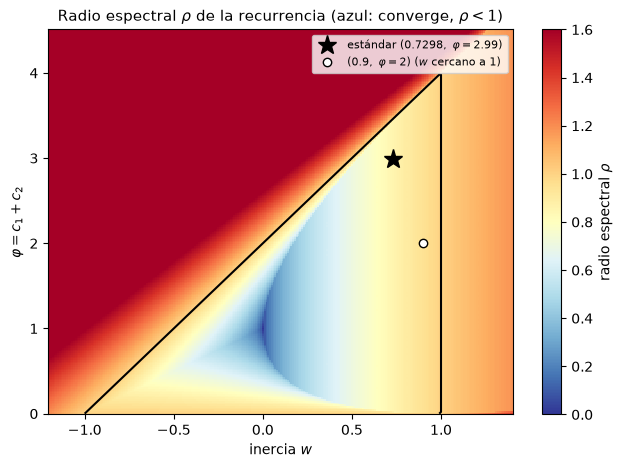

In [5]:
# (a) radio espectral de la matriz de transición [[1+w-phi, -w],[1, 0]] sobre una malla (w, phi)
ws = np.linspace(-1.2, 1.4, 261); phis = np.linspace(0, 4.5, 226)
rho = np.zeros((len(phis), len(ws)))
for i, ph in enumerate(phis):
    for j, w in enumerate(ws):
        rho[i, j] = np.abs(np.linalg.eigvals(np.array([[1 + w - ph, -w], [1, 0]]))).max()
Wg, Pg = np.meshgrid(ws, phis)
teorica = (np.abs(Wg) < 1) & (Pg > 0) & (Pg < 2 * (1 + Wg))
numerica = rho < 1 - 1e-9
print("Desacuerdo entre región numérica (rho<1) y región teórica (triángulo): ", np.mean(numerica != teorica).round(4), "de la malla (solo bordes)")
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.pcolormesh(Wg, Pg, np.minimum(rho, 1.6), shading="auto", cmap="RdYlBu_r", vmin=0, vmax=1.6)
ax.contour(Wg, Pg, rho, levels=[1], colors="k"); ax.plot(0.7298, 2 * 1.49618, "k*", ms=14, label="estándar $(0.7298,\\ \\varphi=2.99)$")
ax.plot(0.9, 2.0, "wo", mec="k", label="$(0.9,\\ \\varphi=2)$ ($w$ cercano a 1)")
ax.set_xlabel("inercia $w$"); ax.set_ylabel(r"$\varphi=c_1+c_2$"); ax.set_title("Radio espectral $\\rho$ de la recurrencia (azul: converge, $\\rho<1$)")
plt.colorbar(im, label=r"radio espectral $\rho$"); ax.legend(fontsize=8, loc="upper right"); ax.grid(False); plt.show()

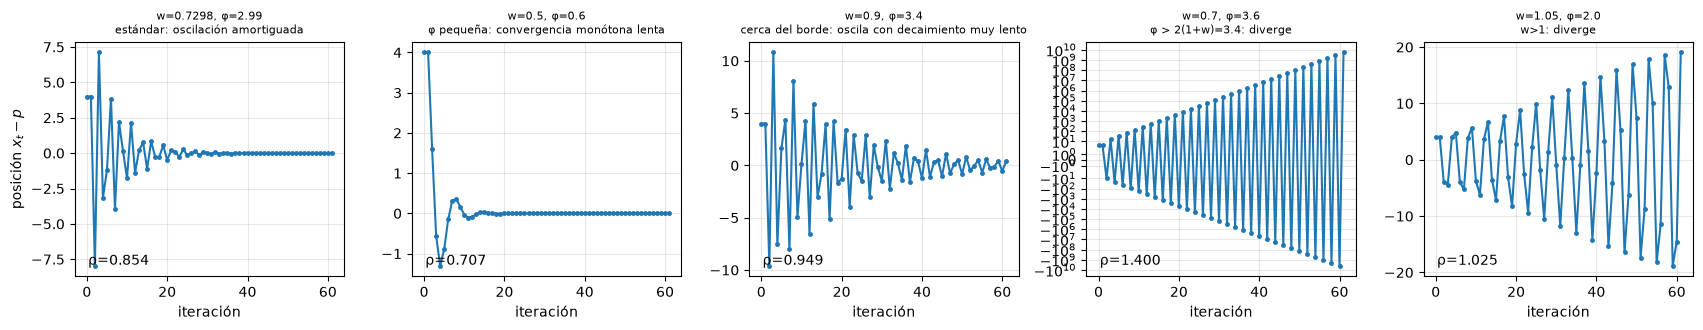

In [6]:
# (b) trayectorias deterministas (x0=4, x_{-1}=4, p=0) para distintos (w, phi)
def traj(w, phi, T=60, x0=4.0):
    x = [x0, x0]
    for _ in range(T): x.append((1 + w - phi) * x[-1] - w * x[-2])
    return np.array(x)
casos = [(0.7298, 2.99, "estándar: oscilación amortiguada"), (0.5, 0.6, "φ pequeña: convergencia monótona lenta"),
         (0.9, 3.4, "cerca del borde: oscila con decaimiento muy lento"), (0.7, 3.6, "φ > 2(1+w)=3.4: diverge"), (1.05, 2.0, "w>1: diverge")]
fig, axs = plt.subplots(1, len(casos), figsize=(17, 3.4), sharey=False)
for ax, (w, ph, tit) in zip(axs, casos):
    xs = traj(w, ph); ax.plot(xs, "o-", ms=2.5); ax.set_title(f"w={w}, φ={ph}\n{tit}", fontsize=8); ax.set_xlabel("iteración")
    ev = np.abs(np.linalg.eigvals(np.array([[1 + w - ph, -w], [1, 0]]))).max(); ax.text(0.05, 0.05, f"ρ={ev:.3f}", transform=ax.transAxes)
    if np.abs(xs).max() > 50: ax.set_yscale("symlog")
axs[0].set_ylabel("posición $x_t - p$"); plt.tight_layout(); plt.show()

Cota de Poli vs. radio espectral del 2º momento: desacuerdos 0 de 3200 puntos de la malla (esperado: solo en el borde).


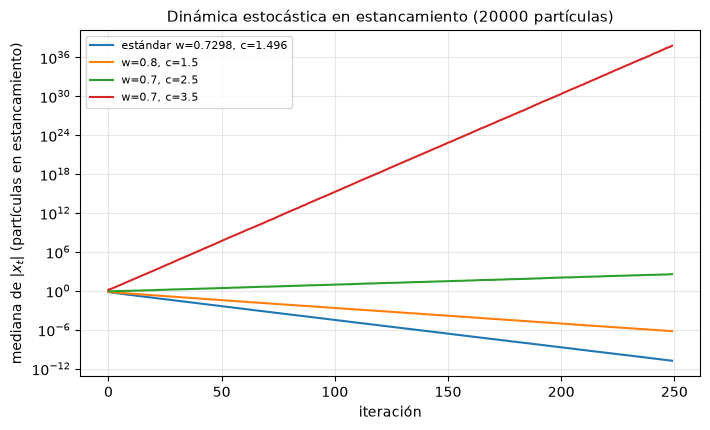

                            c1+c2 media estable (c1+c2<4(1+w)) cota Poli  \
estándar w=0.7298, c=1.496  2.992                         True   3.34748   
w=0.8, c=1.5                  3.0                         True      2.88   
w=0.7, c=2.5                  5.0                         True  3.497143   
w=0.7, c=3.5                  7.0                        False  3.497143   

                           rho 2º momento (teoría)  \
estándar w=0.7298, c=1.496                0.944128   
w=0.8, c=1.5                              1.015763   
w=0.7, c=2.5                              1.598387   
w=0.7, c=3.5                              4.521292   

                           pendiente de E[log10|x|] por iter (simulación)  
estándar w=0.7298, c=1.496                                      -0.042188  
w=0.8, c=1.5                                                    -0.024034  
w=0.7, c=2.5                                                     0.010931  
w=0.7, c=3.5                                

In [7]:
# (c) segundo momento (teoría exacta por matriz 3x3) y exponente de Lyapunov (simulación), r1,r2 ~ U(0,1)
def rho_segundo_momento(w, c1, c2):
    # estado m_t = (E x_t^2, E x_t x_{t-1}, E x_{t-1}^2); a = 1+w-phi con E[a], Var[a] = (c1^2+c2^2)/12
    mu = (c1 + c2) / 2; s2 = (c1 ** 2 + c2 ** 2) / 12; Ea = 1 + w - mu; Ea2 = Ea ** 2 + s2
    M = np.array([[Ea2, -2 * w * Ea, w ** 2], [Ea, -w, 0], [1, 0, 0]])
    return np.abs(np.linalg.eigvals(M)).max()

# comprobación de la cota de Poli en una malla (c1=c2=c): rho_2<1  <=>  c1+c2 < 24(1-w^2)/(7-5w)
desac = 0; tot = 0
for w in np.linspace(-0.95, 0.95, 40):
    for c in np.linspace(0.05, 4.0, 80):
        pred = 2 * c < 24 * (1 - w ** 2) / (7 - 5 * w); num = rho_segundo_momento(w, c, c) < 1
        desac += (pred != num); tot += 1
print(f"Cota de Poli vs. radio espectral del 2º momento: desacuerdos {desac} de {tot} puntos de la malla (esperado: solo en el borde).")

def simular(w, c1, c2, T=250, M=20000, seed=0):
    r = np.random.default_rng(seed); x = r.normal(size=M); v = r.normal(size=M); lg, med = [], []
    for t in range(T):
        v = w * v + (c1 * r.random(M) + c2 * r.random(M)) * (0 - x); x = x + v
        lg.append(np.mean(np.log10(np.abs(x) + 1e-300))); med.append(np.median(np.abs(x)))
    return np.array(lg), np.array(med)

cfgs = {"estándar w=0.7298, c=1.496": (0.7298, 1.496, 1.496), "w=0.8, c=1.5": (0.8, 1.5, 1.5),
        "w=0.7, c=2.5": (0.7, 2.5, 2.5), "w=0.7, c=3.5": (0.7, 3.5, 3.5)}
fig, ax = plt.subplots(figsize=(8, 4.5)); rows = {}
for nombre, (w, c1, c2) in cfgs.items():
    lg, med = simular(w, c1, c2); ax.semilogy(med, label=nombre)
    rows[nombre] = {"c1+c2": c1 + c2, "media estable (c1+c2<4(1+w))": c1 + c2 < 4 * (1 + w), "cota Poli": 24 * (1 - w ** 2) / (7 - 5 * w),
                    "rho 2º momento (teoría)": rho_segundo_momento(w, c1, c2), "pendiente de E[log10|x|] por iter (simulación)": np.polyfit(np.arange(100, 250), lg[100:250], 1)[0]}
ax.set_xlabel("iteración"); ax.set_ylabel("mediana de $|x_t|$ (partículas en estancamiento)"); ax.set_title("Dinámica estocástica en estancamiento (20000 partículas)"); ax.legend(fontsize=8); plt.show()
print(pd.DataFrame(rows).T.round(4))

**Lectura.** La figura de la región es la prueba visual: el radio espectral cruza $\rho=1$ exactamente en el triángulo teórico (el desacuerdo numérico se concentra en el borde). Las trayectorias deterministas muestran el espectro de comportamientos: oscilación amortiguada, convergencia monótona lenta, decaimiento casi nulo cerca del borde y divergencia fuera de él. La cota de Poli coincide con el radio espectral del segundo momento salvo en el borde. En la simulación (tabla), el signo de la **pendiente de $E[\log|x|]$** indica convergencia casi segura (negativa) o divergencia (positiva): la configuración estándar converge con todas las garantías; las configuraciones con $c_1+c_2$ por encima de la cota de Poli tienen **varianza divergente** (columna de $\rho$ del 2º momento mayor que 1) aunque en algunos casos las trayectorias individuales todavía converjan casi seguramente (pendiente negativa): son configuraciones "borde" donde el enjambre real explora con amplitud grande y errática. Con $c$ aún mayor, ambas medidas son inestables.

> **Conclusión práctica**: elegir $(w,c_1,c_2)$ por sentido común es peligroso. El par estándar $(0.7298,\ 1.496)$, o $\chi=0.7298$ con $c_{1,2}=2.05$, es un punto seguro. (El análisis supone estancamiento —$p$ y $g$ fijos—; el PSO real interactúa con la actualización de $p,g$ y es más complejo.)

## 4. Evolución diferencial (DE)

### Intuición
DE (Storn & Price, 1997) usa **diferencias entre individuos de la población** como paso de mutación: si la población está dispersa, los pasos son grandes (exploración); cuando converge, las diferencias se achican y el paso se **autoescala**. No hay distribución de mutación externa.

### Formulación (DE/rand/1/bin)
Para cada individuo $x_i$ (vector objetivo) con $NP$ individuos:
1. **Mutación**: se eligen $r_1,r_2,r_3$ distintos entre sí y de $i$: $\ v_i=x_{r_1}+F\,(x_{r_2}-x_{r_3})$, con $F\in(0,2]$ típicamente $0.4$–$0.9$.
2. **Cruce binomial**: $u_{ij}=v_{ij}$ si $\operatorname{rand}_j<CR$ o $j=j_{\text{rand}}$; si no, $u_{ij}=x_{ij}$. $j_{\text{rand}}$ garantiza que al menos un gen viene del mutante.
3. **Selección voraz**: $x_i\leftarrow u_i$ si $f(u_i)\le f(x_i)$.

**Variantes** (notación DE/base/nº de diferencias/cruce): `rand/1/bin` (robusta, exploratoria), `best/1/bin`: $v_i=x_{best}+F(x_{r_1}-x_{r_2})$ (convergencia rápida, riesgo de prematura), `current-to-best/1`: $v_i=x_i+F(x_{best}-x_i)+F(x_{r_1}-x_{r_2})$.

**Efecto de $CR$**: $CR$ bajo cambia pocas coordenadas por vez (bueno para funciones **separables**, como Rastrigin); $CR$ alto cambia casi todas (mejor para funciones con dependencia entre variables, como Rosenbrock y Ackley rotada). La selección uno a uno de DE es *elitista por individuo*: ningún objetivo empeora.

In [8]:
def de(f, lo, hi, D, NP=40, evals=20000, F=0.5, CR=0.9, strategy="rand/1", seed=0, snaps=None):
    # Evolución diferencial vectorizada, cruce binomial. f(X:(NP,D))->(NP,).
    # strategy: 'rand/1' | 'best/1' | 'current-to-best/1'
    rng = np.random.default_rng(seed); ar = np.arange(NP)
    X = lo + (hi - lo) * rng.random((NP, D)); fx = f(X); used = NP
    ev, best = [used], [fx.min()]; saved = {}; t = 0
    if snaps is not None and 0 in snaps: saved[0] = (X.copy(), X[fx.argmin()].copy())
    while used + NP <= evals:
        t += 1
        Rm = rng.random((NP, NP)); np.fill_diagonal(Rm, np.inf)
        r1, r2, r3 = np.argsort(Rm, axis=1)[:, :3].T                   # tres índices distintos entre sí y distintos de i
        b = X[fx.argmin()]
        if strategy == "rand/1":                V = X[r1] + F * (X[r2] - X[r3])
        elif strategy == "best/1":              V = b + F * (X[r1] - X[r2])
        elif strategy == "current-to-best/1":   V = X + F * (b - X) + F * (X[r1] - X[r2])
        else: raise ValueError(strategy)
        cruz = rng.random((NP, D)) < CR; cruz[ar, rng.integers(0, D, NP)] = True     # jrand
        U = np.where(cruz, V, X)
        U = np.where(U < lo, (X + lo) / 2, U); U = np.where(U > hi, (X + hi) / 2, U)  # reparación: punto medio con el padre
        fu = f(U); used += NP
        mej = fu <= fx; X[mej], fx[mej] = U[mej], fu[mej]
        ev.append(used); best.append(fx.min())
        if snaps is not None and t in snaps: saved[t] = (X.copy(), X[fx.argmin()].copy())
    i = fx.argmin()
    return dict(ev=np.array(ev), best=np.array(best), x=X[i].copy(), f=fx[i], snaps=saved)

r = de(rastrigin, -5.12, 5.12, 10, NP=50, evals=20000, seed=0)
print("DE rand/1/bin en Rastrigin 10D con 20000 evaluaciones -> f =", round(r["f"], 4))

DE rand/1/bin en Rastrigin 10D con 20000 evaluaciones -> f = 32.961


In [9]:
# ---- Validación de DE ----
rng = np.random.default_rng(0)
# (i) los tres índices son distintos entre sí y de i
NP = 30
for _ in range(500):
    Rm = rng.random((NP, NP)); np.fill_diagonal(Rm, np.inf); idx = np.argsort(Rm, axis=1)[:, :3]
    assert all(len(set(idx[i]) | {i}) == 4 for i in range(NP))
print("(i) r1,r2,r3 siempre distintos entre sí y de i (500 repeticiones).")
# (ii) jrand: con CR=0 el vector de prueba difiere del objetivo en exactamente 1 coordenada
cruz = rng.random((NP, 10)) < 0.0; cruz[np.arange(NP), rng.integers(0, 10, NP)] = True
assert np.all(cruz.sum(1) == 1); print("(ii) Con CR=0, exactamente 1 gen proviene del mutante (jrand).")
# (iii) elitismo por individuo y respeto de la caja
r = de(sphere, -5, 5, 10, NP=30, evals=15000, seed=3, snaps=[0, 10, 100])
assert np.all(np.diff(r["best"]) <= 1e-15) and all(np.all(S >= -5) and np.all(S <= 5) for S, _ in r["snaps"].values())
print("(iii) mejor monótono y soluciones dentro de la caja. DE en esfera 10D: f final =", f"{r['f']:.2e}")
for estr in ["rand/1", "best/1", "current-to-best/1"]:
    print(f"    {estr:18s} Rastrigin 10D (NP=50, 20000 ev): f =", round(de(rastrigin, -5.12, 5.12, 10, NP=50, strategy=estr, seed=1)["f"], 3))

(i) r1,r2,r3 siempre distintos entre sí y de i (500 repeticiones).
(ii) Con CR=0, exactamente 1 gen proviene del mutante (jrand).
(iii) mejor monótono y soluciones dentro de la caja. DE en esfera 10D: f final = 8.59e-24
    rand/1             Rastrigin 10D (NP=50, 20000 ev): f = 30.864


    best/1             Rastrigin 10D (NP=50, 20000 ev): f = 16.088


    current-to-best/1  Rastrigin 10D (NP=50, 20000 ev): f = 7.385


## 5. Visualización: instantáneas del enjambre

Mostramos la población en iteraciones seleccionadas sobre las curvas de nivel en 2D (población de 20, iteraciones 0, 3, 10 y 30). La estrella roja es el mejor encontrado hasta ese momento. Fíjate en cómo PSO se concentra en una región alrededor del líder (con partículas que **sobrepasan** y oscilan), mientras que DE conserva grupos en varias cuencas y se contrae a medida que las diferencias se reducen.

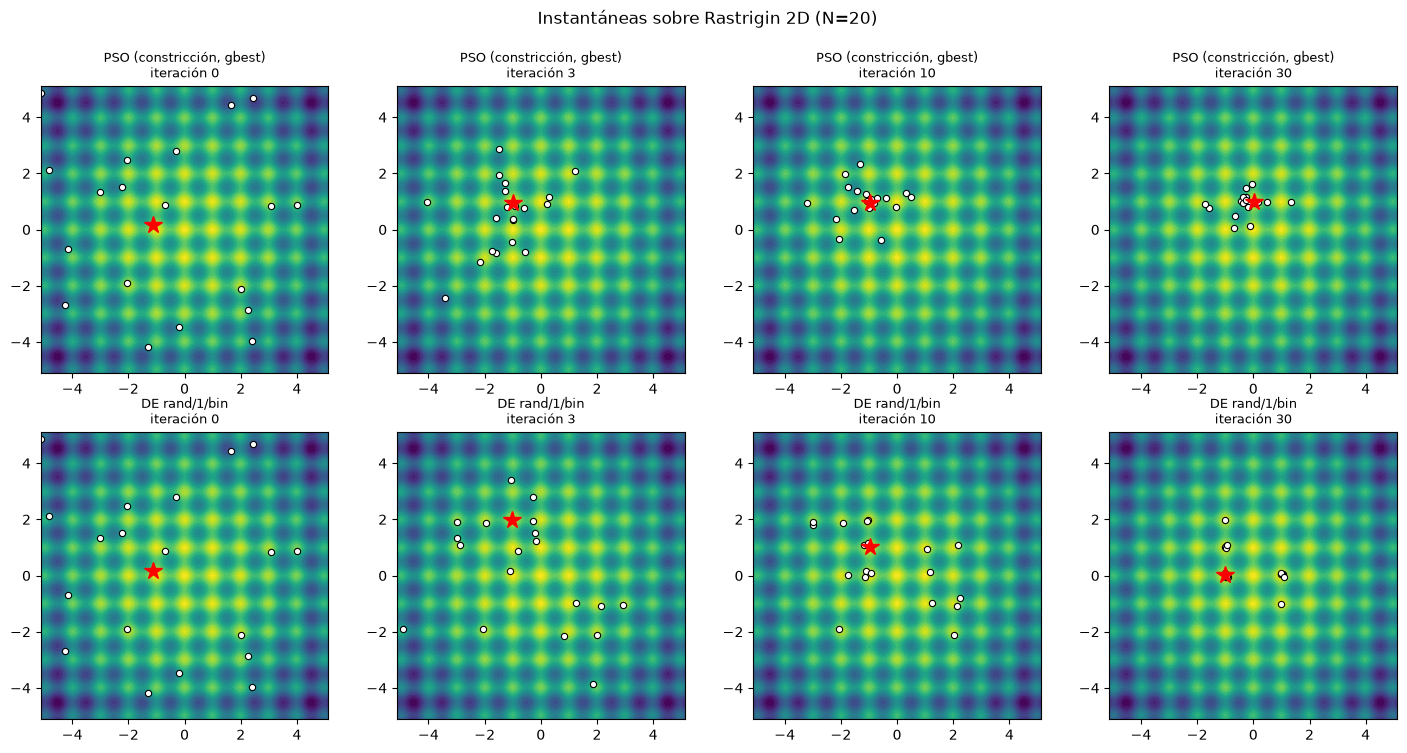

In [10]:
def instantaneas(nombre, snaps=(0, 3, 10, 30), N=20, seed=3):
    f, lo, hi, _ = FUNCS[nombre]
    rp = pso(f, lo, hi, 2, N=N, evals=N * (max(snaps) + 2), seed=seed, snaps=list(snaps), chi=True, c1=2.05, c2=2.05)
    rd = de(f, lo, hi, 2, NP=N, evals=N * (max(snaps) + 2), seed=seed, F=0.6, CR=0.9, snaps=list(snaps))
    fig, axs = plt.subplots(2, len(snaps), figsize=(3.6 * len(snaps), 7.4))
    for row, (res, tit) in enumerate([(rp, "PSO (constricción, gbest)"), (rd, "DE rand/1/bin")]):
        for col, t in enumerate(snaps):
            ax = axs[row, col]; contornos(ax, nombre, n=200); X, b = res["snaps"][t]
            ax.plot(X[:, 0], X[:, 1], "w.", mec="k", ms=9, mew=0.8); ax.plot(b[0], b[1], "r*", ms=13)
            a_, b_ = VIEW[nombre]; ax.set_xlim(a_, b_); ax.set_ylim(a_, b_); ax.set_title(f"{tit}\niteración {t}", fontsize=9)
    plt.suptitle(f"Instantáneas sobre {nombre} 2D (N={N})", y=1.0); plt.tight_layout(); plt.show()
    return rp, rd
_ = instantaneas("Rastrigin")

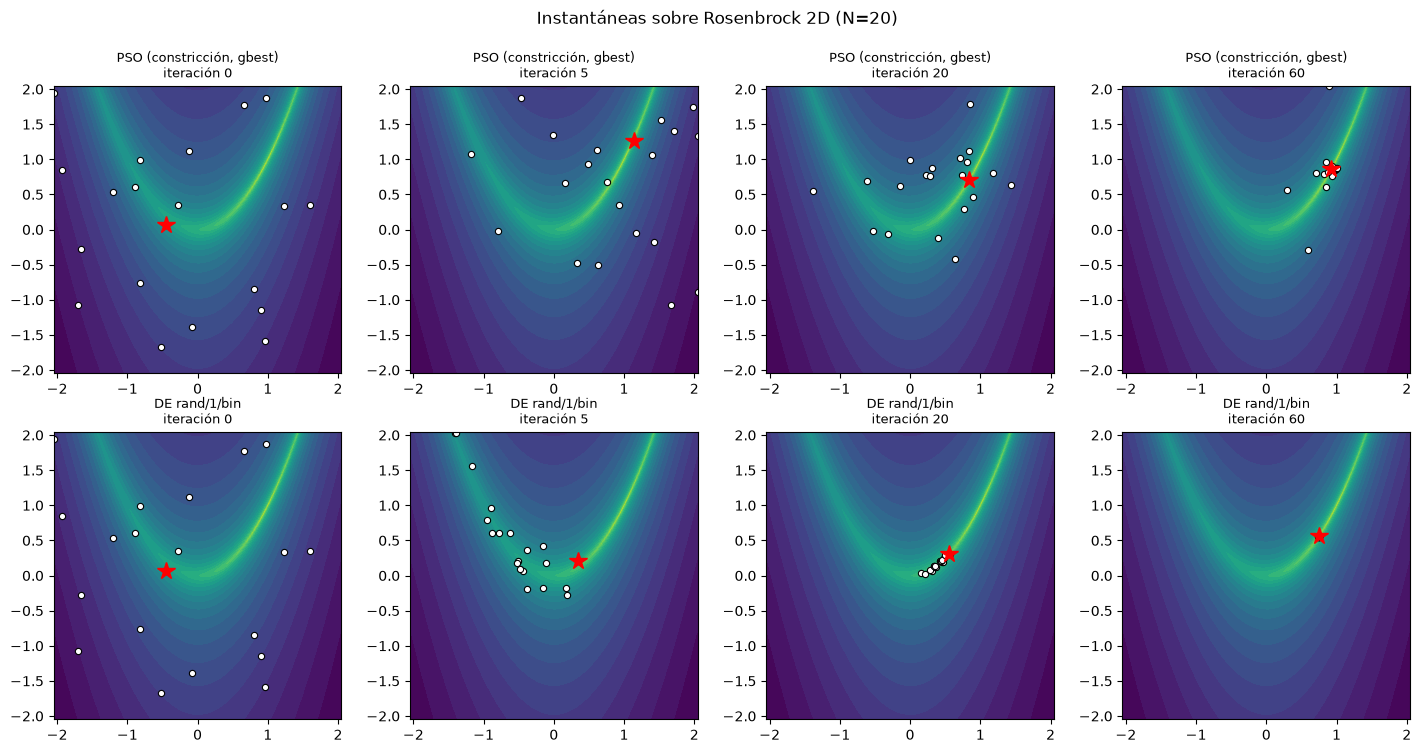

In [11]:
_ = instantaneas("Rosenbrock", snaps=(0, 5, 20, 60))

**Lectura.** En Rastrigin 2D, ambos algoritmos se agrupan en torno a una de las muchas cuencas; con una población de 20 no es seguro que sea la global: depende de la semilla y por eso en la sección 7 se promedia sobre muchas semillas. En Rosenbrock se aprecia la dificultad del **valle curvo** (franja clara, valores bajos): ambos algoritmos llegan rápido al valle, pero avanzar *a lo largo* de él hasta $(1,1)$ exige coordinar las dos variables. Las instantáneas muestran dos comportamientos distintos: el PSO conserva un enjambre disperso alrededor del líder que oscila a través del valle, mientras que DE, al usar diferencias entre individuos que ya están en el valle, genera pasos **alineados con su dirección** (adaptación implícita de la forma de la distribución), pero su población se **contrae muy rápido** y en la iteración 60 está casi concentrada en un punto del valle, antes de llegar al óptimo: un ejemplo visual de pérdida de diversidad (convergencia prematura) que veremos reflejado en las curvas.

## 6. Un AG de codificación real como tercer competidor

Para una comparación justa incluimos un AG real vectorizado: torneo $k=3$, **cruce SBX** (*simulated binary crossover*, $\eta=15$, probabilidad por gen 0.5), mutación gaussiana con probabilidad $1/D$ por gen y desviación $0.05(u-l)$, y elitismo de 2. SBX produce hijos con una distribución alrededor de los padres análoga a la del cruce de un punto binario (Deb & Agrawal, 1995).

In [12]:
def ga_real(f, lo, hi, D, N=50, evals=20000, pc=0.9, eta=15.0, k=3, sigma_frac=0.05, n_elite=2, seed=0):
    rng = np.random.default_rng(seed); R = hi - lo; ar = np.arange(N)
    X = lo + R * rng.random((N, D)); fx = f(X); used = N; ev, best = [used], [fx.min()]
    while used + N - n_elite <= evals:
        cand = rng.integers(0, N, (N, k)); sel = cand[ar, np.argmin(fx[cand], axis=1)]
        P1, P2 = X[sel[: N // 2]], X[sel[N // 2: 2 * (N // 2)]]
        u = rng.random(P1.shape); beta = np.where(u <= 0.5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u) + 1e-300)) ** (1 / (eta + 1)))
        C1 = 0.5 * ((1 + beta) * P1 + (1 - beta) * P2); C2 = 0.5 * ((1 - beta) * P1 + (1 + beta) * P2)
        usar = (rng.random((N // 2, 1)) < pc) & (rng.random(P1.shape) < 0.5)             # SBX por gen con prob 0.5, por pareja con prob pc
        C1, C2 = np.where(usar, C1, P1), np.where(usar, C2, P2)
        Y = np.vstack([C1, C2])
        mut = rng.random(Y.shape) < 1.0 / D; Y = Y + mut * sigma_frac * R * rng.standard_normal(Y.shape)
        Y = np.clip(Y, lo, hi)
        fy = f(Y); used += len(Y)
        e = np.argsort(fx)[:n_elite]; w = np.argsort(fy)[: len(Y) - n_elite]
        X = np.vstack([X[e], Y[w]]); fx = np.r_[fx[e], fy[w]]
        # (se descartan los peores hijos para conservar la élite)
        ev.append(used - n_elite * 0); best.append(fx.min())
    i = fx.argmin()
    return dict(ev=np.array(ev), best=np.array(best), x=X[i].copy(), f=fx[i])

r = ga_real(rastrigin, -5.12, 5.12, 10, evals=20000, seed=0); print("GA real en Rastrigin 10D (20000 ev): f =", round(r["f"], 3))
r = ga_real(sphere, -5, 5, 10, evals=20000, seed=0); assert np.all(np.diff(r["best"]) <= 1e-15); print("GA real en esfera 10D: f =", f"{r['f']:.2e}", "(monótono: OK)")

GA real en Rastrigin 10D (20000 ev): f = 0.0
GA real en esfera 10D: f = 1.93e-06 (monótono: OK)


## 7. Comparación PSO vs. DE vs. GA real

Protocolo: 5 algoritmos, 3 funciones, $D\in\{10,30\}$, **15 semillas** por combinación, presupuesto de evaluaciones fijo ($40\,000$ para $D=10$; $120\,000$ para $D=30$). Parámetros "estándar" (sin ajuste por función):
- PSO: constricción $\chi$ con $c_1=c_2=2.05$ ($N=40$ en 10D, $N=60$ en 30D), topologías *gbest* y *ring*;
- DE: $F=0.5$, $CR=0.9$, $NP=50$ (10D) / $100$ (30D), estrategias `rand/1/bin` y `best/1/bin`;
- GA real: población 50 / 100.

Reportamos media $\pm$ desviación del valor final y curvas (mediana con banda intercuartílica, en escala log).

In [13]:
ALGOS = ["PSO gbest (χ)", "PSO anillo (χ)", "DE rand/1/bin", "DE best/1/bin", "GA real (SBX)"]
CFGD = {10: dict(evals=40000, N=40, NP=50, Ng=50), 30: dict(evals=120000, N=60, NP=100, Ng=100)}
def correr_una(task):
    algo, fn, D, seed = task; f, lo, hi, _ = FUNCS[fn]; c = CFGD[D]
    if algo == "PSO gbest (χ)":   return task, pso(f, lo, hi, D, N=c["N"], evals=c["evals"], chi=True, c1=2.05, c2=2.05, topo="gbest", seed=seed)
    if algo == "PSO anillo (χ)":  return task, pso(f, lo, hi, D, N=c["N"], evals=c["evals"], chi=True, c1=2.05, c2=2.05, topo="ring", seed=seed)
    if algo == "DE rand/1/bin":   return task, de(f, lo, hi, D, NP=c["NP"], evals=c["evals"], F=0.5, CR=0.9, strategy="rand/1", seed=seed)
    if algo == "DE best/1/bin":   return task, de(f, lo, hi, D, NP=c["NP"], evals=c["evals"], F=0.5, CR=0.9, strategy="best/1", seed=seed)
    return task, ga_real(f, lo, hi, D, N=c["Ng"], evals=c["evals"], seed=seed)

SEEDS = list(range(15))
t0 = time.time()
out = pmap(correr_una, [(a, fn, D, s) for a in ALGOS for fn in FUNCS for D in (10, 30) for s in SEEDS], procs=12)
RES = {}
for (a, fn, D, s), r in out: RES.setdefault((fn, D, a), []).append(r)
print(f"{len(out)} ejecuciones en {time.time()-t0:.0f}s")
# comprobación de coherencia: valor devuelto = recomputación de f en x
for (fn, D, a), L in RES.items():
    for r in L[:2]: assert abs(FUNCS[fn][0](r["x"][None])[0] - r["f"]) < 1e-8 * max(1, abs(r["f"]))
print("Valores finales coherentes con la recomputación de f(x).")

450 ejecuciones en 14s
Valores finales coherentes con la recomputación de f(x).


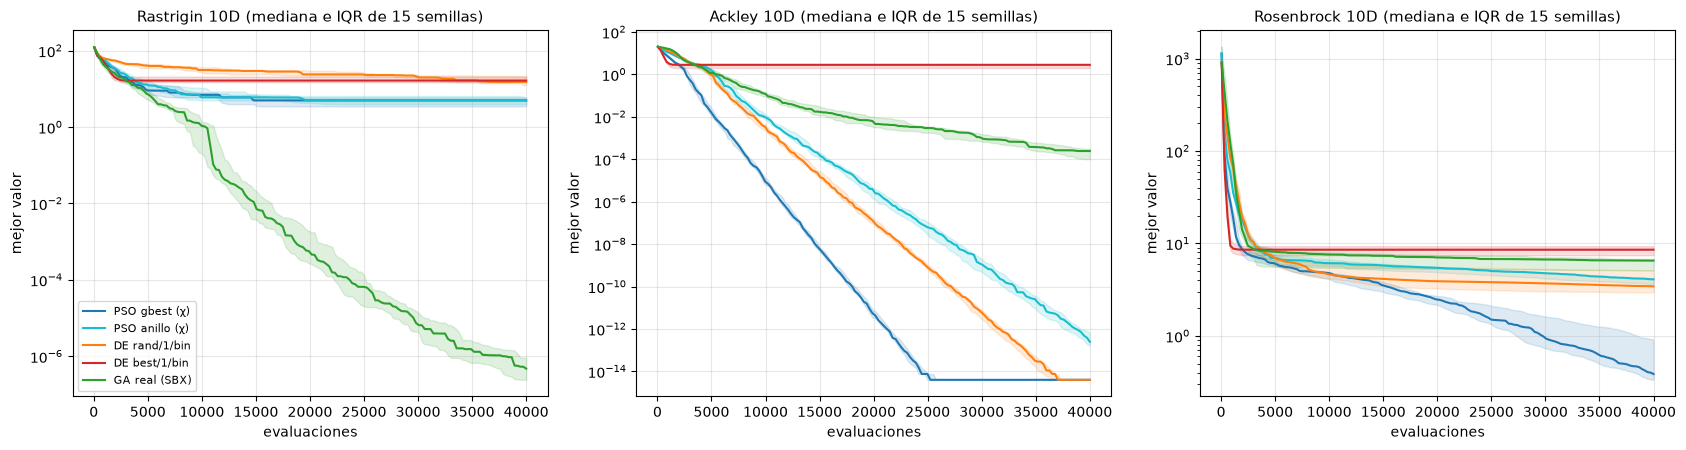

In [14]:
def graficar(D):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.6)); cols = ["C0", "C9", "C1", "C3", "C2"]
    for ax, fn in zip(axs, FUNCS):
        for a, c in zip(ALGOS, cols):
            L = RES[(fn, D, a)]; g = np.linspace(L[0]["ev"][0] + 1, CFGD[D]["evals"], 150)
            C = np.array([r["best"][np.clip(np.searchsorted(r["ev"], g, side="right") - 1, 0, None)] for r in L])
            C = np.maximum(C, 1e-16); q1, q2, q3 = np.percentile(C, [25, 50, 75], axis=0)
            ax.semilogy(g, q2, color=c, label=a); ax.fill_between(g, q1, q3, color=c, alpha=0.15)
        ax.set_title(f"{fn} {D}D (mediana e IQR de 15 semillas)"); ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor valor")
    axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
graficar(10)

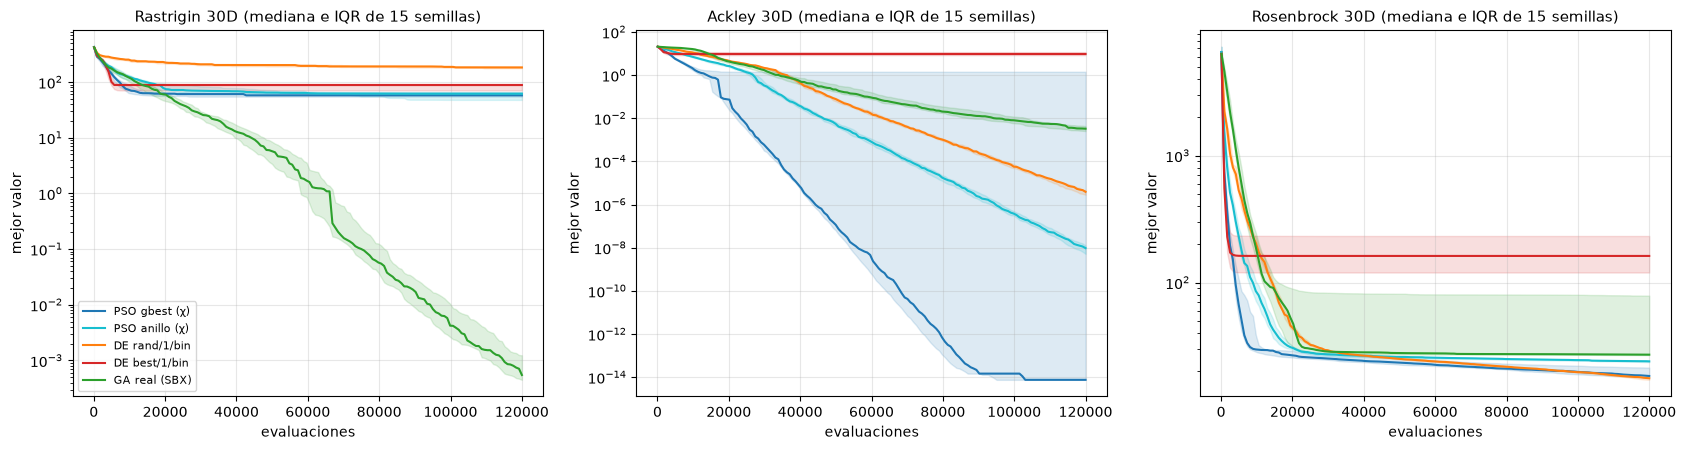

In [15]:
graficar(30)

In [16]:
def tabla_final(D):
    rows = {}
    for fn in FUNCS:
        for a in ALGOS:
            v = np.array([r["f"] for r in RES[(fn, D, a)]]); rows[(fn, a)] = {"media": v.mean(), "desv.": v.std(ddof=1), "mediana": np.median(v), "mejor": v.min()}
    df = pd.DataFrame(rows).T
    return df.map(lambda z: f"{z:.3g}") if hasattr(df, "map") else df.applymap(lambda z: f"{z:.3g}")
print("=== D = 10 ==="); print(tabla_final(10)); print("\n=== D = 30 ==="); print(tabla_final(30))
# Ranking medio por función y dimensión (menor = mejor), según la media del valor final
rk = {}
for D in (10, 30):
    for fn in FUNCS:
        m = pd.Series({a: np.mean([r["f"] for r in RES[(fn, D, a)]]) for a in ALGOS}); rk[(fn, D)] = m.rank()
print("\nRanking por la media final (1 = mejor):"); print(pd.DataFrame(rk).T)

=== D = 10 ===
                              media     desv.   mediana     mejor
Rastrigin  PSO gbest (χ)        5.7      3.73      4.97      1.99
           PSO anillo (χ)       5.3      2.34      4.93      2.98
           DE rand/1/bin       16.6      6.23      15.2      6.49
           DE best/1/bin       17.2       5.2      16.5      6.98
           GA real (SBX)   9.35e-07  1.46e-06  4.75e-07  3.88e-08
Ackley     PSO gbest (χ)      4e-15         0     4e-15     4e-15
           PSO anillo (χ)  4.61e-13   4.8e-13  2.49e-13  6.44e-14
           DE rand/1/bin      4e-15         0     4e-15     4e-15
           DE best/1/bin       2.33      1.19      2.81    0.0132
           GA real (SBX)   0.000208  0.000124  0.000243  2.79e-05
Rosenbrock PSO gbest (χ)        1.1      1.72     0.387    0.0013
           PSO anillo (χ)      3.65     0.971      4.09     0.799
           DE rand/1/bin       3.79      1.53      3.43   0.00493
           DE best/1/bin       11.4      13.9      8.56      

**Lectura (contrastada con las tablas, el ranking y las curvas).** No hay un algoritmo uniformemente mejor; lo que se observa es:
- **Ackley**: PSO *gbest* y DE `rand/1/bin` alcanzan el óptimo a precisión de máquina en 10D (desviación 0 en todas las semillas); en 30D el PSO con anillo y DE `rand/1` llegan a valores muy pequeños, mientras PSO *gbest* tiene una media peor porque algunas semillas quedan atrapadas (su **mediana** es mucho mejor que su media: distribución muy asimétrica). **DE `best/1/bin` es el peor**: la mutación centrada en el mejor colapsa la diversidad (convergencia prematura).
- **Rosenbrock** (no separable): PSO *gbest* es el mejor en 10D por media; en 30D DE `rand/1/bin` es el mejor con baja variabilidad, seguido de cerca por PSO. DE `best/1` vuelve a ser muy malo.
- **Rastrigin**: el **GA real es, con diferencia, el mejor** y llega a valores casi nulos, mientras PSO queda en valores intermedios y DE `rand/1` con $CR=0.9$ es de los peores. Este resultado **no debe leerse como superioridad general del GA**: Rastrigin es **separable** y el cruce/mutación por gen del GA explota esa estructura (recombina coordenadas bien resueltas), y además el óptimo está en el **centro** de la caja, posición que algunos operadores favorecen sin querer. Lo comprobamos en la celda siguiente.
- Al pasar de 10D a 30D todos empeoran en las funciones difíciles (maldición de la dimensionalidad), pero no igual: DE `rand/1` se degrada mucho en Rastrigin y poco en Rosenbrock.
Las desviaciones son grandes en las funciones multimodales (distribuciones asimétricas), por eso se muestran también mediana y mejor.

### ¿Estructura o sesgo del problema? Función desplazada y rotada
Dos controles estándar: (1) **desplazar** el óptimo fuera del centro de la caja (descarta el sesgo hacia el centro; Monson & Seppi, 2005, lo documentaron para PSO) y (2) **rotar** además el espacio con una matriz ortogonal aleatoria (rompe la separabilidad: las coordenadas ya no se pueden resolver de a una). Repetimos 10D, 40 000 evaluaciones, 10 semillas, con Rastrigin y Ackley.

In [17]:
# Controles: óptimo desplazado y espacio rotado (óptimo en s dentro de [-2,2]^D)
D = 10; rs = np.random.default_rng(99)
SHIFT = rs.uniform(-2, 2, D); Q, _ = np.linalg.qr(rs.normal(size=(D, D)))
assert np.allclose(Q @ Q.T, np.eye(D))
VARIANTES = {}
for nombre in ("Rastrigin", "Ackley"):
    base = FUNCS[nombre][0]
    VARIANTES[(nombre, "original")] = base
    VARIANTES[(nombre, "desplazada")] = (lambda X, base=base: base(np.atleast_2d(X) - SHIFT))
    VARIANTES[(nombre, "desplazada y rotada")] = (lambda X, base=base: base((np.atleast_2d(X) - SHIFT) @ Q.T))
for (nombre, v), f in VARIANTES.items():
    if v != "original": assert abs(f(SHIFT[None])[0]) < 1e-9          # el óptimo está en s (valor ~0)

def tarea_var(task):
    algo, nombre, v, seed = task; f = VARIANTES[(nombre, v)]; lo, hi = FUNCS[nombre][1], FUNCS[nombre][2]; c = CFGD[10]
    if algo == "PSO gbest (χ)":  r = pso(f, lo, hi, D, N=c["N"], evals=c["evals"], chi=True, c1=2.05, c2=2.05, topo="gbest", seed=seed)
    elif algo == "DE rand/1/bin": r = de(f, lo, hi, D, NP=c["NP"], evals=c["evals"], F=0.5, CR=0.9, seed=seed)
    else:                         r = ga_real(f, lo, hi, D, N=c["Ng"], evals=c["evals"], seed=seed)
    return task, r["f"]
AL3 = ["PSO gbest (χ)", "DE rand/1/bin", "GA real (SBX)"]
t0 = time.time()
out = pmap(tarea_var, [(a, n, v, s) for a in AL3 for (n, v) in VARIANTES for s in range(10)], procs=12)
print(f"({time.time()-t0:.0f}s)")
tab = {}
for (a, n, v, s), val in out: tab.setdefault((n, v), {}).setdefault(a, []).append(val)
df = pd.DataFrame({k: {a: f"{np.mean(v):.3g} ± {np.std(v, ddof=1):.2g}" for a, v in d_.items()} for k, d_ in tab.items()}).T
print(df)

(2s)
                              PSO gbest (χ) DE rand/1/bin       GA real (SBX)
Rastrigin original                 6.57 ± 4    17.5 ± 6.1    6.27e-07 ± 5e-07
          desplazada             5.27 ± 2.8    13.7 ± 6.9  5.04e-07 ± 4.9e-07
          desplazada y rotada    19.5 ± 8.1       18 ± 11           37.4 ± 10
Ackley    original                4e-15 ± 0     4e-15 ± 0  0.000264 ± 0.00011
          desplazada              4e-15 ± 0     4e-15 ± 0  0.000221 ± 0.00021
          desplazada y rotada  0.762 ± 0.84     4e-15 ± 0         1.68 ± 0.69


**Lectura.** El **desplazamiento** apenas cambia nada (los valores de las filas "original" y "desplazada" son del mismo orden para los tres algoritmos), así que en este benchmark no hay un sesgo apreciable al centro. La **rotación**, en cambio, tiene un efecto enorme: el GA real, que era el mejor por varios órdenes de magnitud en Rastrigin, pasa a ser el *peor* en la versión rotada, porque sus operadores por coordenada ya no pueden resolver las dimensiones de a una. Es decir, su ventaja venía de la **separabilidad**, no de una superioridad general. DE con $CR=0.9$ resulta mucho menos sensible a la rotación (en Ackley rotada es el único que sigue a precisión de máquina), y el PSO se degrada de forma intermedia. **Moraleja metodológica**: una conclusión de benchmark sobre funciones separables y simétricas respecto al origen puede ser un artefacto del benchmark; hay que incluir controles de desplazamiento y rotación.

## 8. Sensibilidad a parámetros

Barrido sobre **Rastrigin 10D** (presupuesto 40 000, 8 semillas): para PSO, la inercia $w$ y los coeficientes $c_1=c_2=c$ (sin constricción) y la topología; para DE, la rejilla $F\times CR$. Una celda muestra $\log_{10}$ del valor final medio (menor es mejor).

(3s)


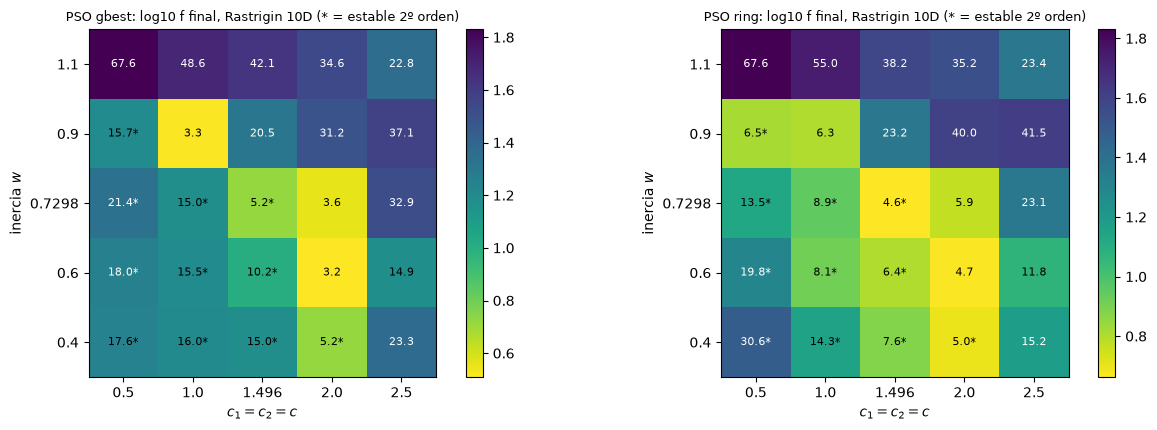

Celdas con * cumplen la cota de estabilidad de 2º orden de Poli: c1+c2 < 24(1-w^2)/(7-5w) con |w|<1.


In [18]:
def tarea_pso_grid(task):
    w, c, topo, s = task
    return task, pso(rastrigin, -5.12, 5.12, 10, N=40, evals=40000, w=w, c1=c, c2=c, topo=topo, seed=s)["f"]
WS = [0.4, 0.6, 0.7298, 0.9, 1.1]; CS = [0.5, 1.0, 1.496, 2.0, 2.5]
t0 = time.time()
out = pmap(tarea_pso_grid, [(w, c, t, s) for t in ("gbest", "ring") for w in WS for c in CS for s in range(8)], procs=12)
print(f"({time.time()-t0:.0f}s)")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, topo in zip(axs, ("gbest", "ring")):
    Z = np.array([[np.mean([v for (w_, c_, t_, s_), v in out if (w_, c_, t_) == (w, c, topo)]) for c in CS] for w in WS])
    im = ax.imshow(np.log10(Z + 1e-9), cmap="viridis_r", origin="lower"); ax.grid(False)
    ax.set_xticks(range(len(CS))); ax.set_xticklabels(CS); ax.set_yticks(range(len(WS))); ax.set_yticklabels(WS)
    ax.set_xlabel("$c_1=c_2=c$"); ax.set_ylabel("inercia $w$"); ax.set_title(f"PSO {topo}: log10 f final, Rastrigin 10D (* = estable 2º orden)", fontsize=9)
    for i in range(len(WS)):
        for j in range(len(CS)):
            estable2 = (WS[i] < 1) and (2 * CS[j] < 24 * (1 - WS[i] ** 2) / (7 - 5 * WS[i]))          # cota de Poli (2º orden)
            ax.text(j, i, f"{Z[i, j]:.1f}" + ("*" if estable2 else ""), ha="center", va="center", color="w" if Z[i, j] > np.median(Z) else "k", fontsize=8)
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
print("Celdas con * cumplen la cota de estabilidad de 2º orden de Poli: c1+c2 < 24(1-w^2)/(7-5w) con |w|<1.")

(4s)


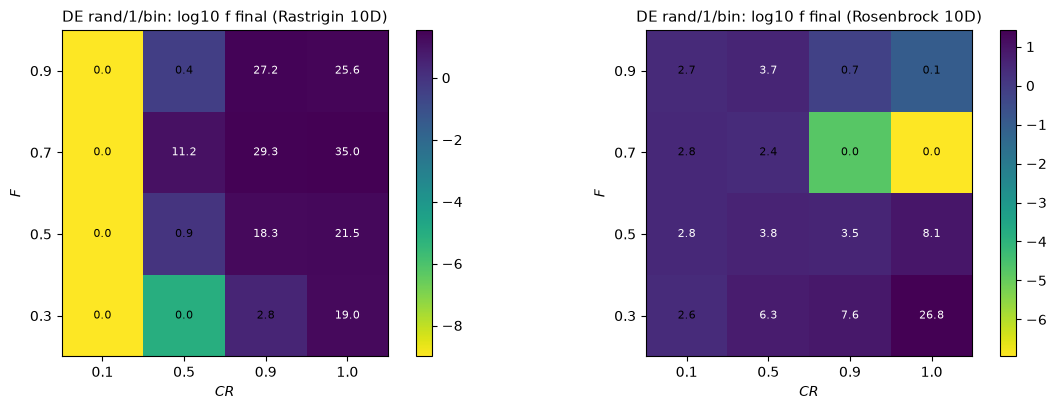

In [19]:
def tarea_de_grid(task):
    F, CR, fn, s = task; f, lo, hi, _ = FUNCS[fn]
    return task, de(f, lo, hi, 10, NP=50, evals=40000, F=F, CR=CR, seed=s)["f"]
FS = [0.3, 0.5, 0.7, 0.9]; CRS = [0.1, 0.5, 0.9, 1.0]
t0 = time.time()
out = pmap(tarea_de_grid, [(F, CR, fn, s) for fn in ("Rastrigin", "Rosenbrock") for F in FS for CR in CRS for s in range(8)], procs=12)
print(f"({time.time()-t0:.0f}s)")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, fn in zip(axs, ("Rastrigin", "Rosenbrock")):
    Z = np.array([[np.mean([v for (F_, C_, f_, s_), v in out if (F_, C_, f_) == (F, CR, fn)]) for CR in CRS] for F in FS])
    im = ax.imshow(np.log10(Z + 1e-9), cmap="viridis_r", origin="lower"); ax.grid(False)
    ax.set_xticks(range(len(CRS))); ax.set_xticklabels(CRS); ax.set_yticks(range(len(FS))); ax.set_yticklabels(FS)
    ax.set_xlabel("$CR$"); ax.set_ylabel("$F$"); ax.set_title(f"DE rand/1/bin: log10 f final ({fn} 10D)")
    for i in range(len(FS)):
        for j in range(len(CRS)): ax.text(j, i, f"{Z[i, j]:.1f}", ha="center", va="center", color="w" if Z[i, j] > np.median(Z) else "k", fontsize=8)
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

**Lectura.** (Contrastar con los mapas de calor.) Las celdas marcadas con `*` cumplen la cota de estabilidad de segundo orden; las celdas con $w=1.1$ (inercia $>1$) son inestables por construcción y son visiblemente las peores. Fuera de esa fila, la relación entre la cota de estabilidad y el rendimiento **no es un corte nítido**: en una función multimodal como Rastrigin, cierta "inestabilidad" (mayor amplitud de exploración) puede ser útil, y los valores pequeños de $c$ hacen que el enjambre converja demasiado pronto a un mínimo local. Compara la topología gbest con la de anillo para ver cuál tolera mejor los parámetros extremos. Para DE, los mapas muestran que el efecto de $F$ y $CR$ difiere entre una función separable (Rastrigin) y una no separable (Rosenbrock): fíjate en qué dirección se mueve la zona buena en cada una. En ambos casos importa tanto el **tamaño de la zona buena** del espacio de parámetros como el óptimo puntual: una configuración robusta es preferible a una afinada para un solo problema (tema del [notebook 15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)).

## 9. PSO discreto / de permutaciones para TSP

### Idea
En permutaciones no existen $+$, $-$ ni $\times$ por escalar, pero se pueden **redefinir** esas operaciones (Clerc, 2004):
- **Posición**: una permutación $x$.
- **Diferencia** $y\ominus x$: una **secuencia de swaps** $s=(i_1,j_1),\dots,(i_m,j_m)$ tal que aplicarla a $x$ produce $y$ (con $m\le n-1$). Es el "vector diferencial" de las permutaciones.
- **Velocidad**: una secuencia de swaps.
- **Producto por escalar** $c\otimes s$: conservar cada swap de $s$ con probabilidad $c\in[0,1]$.
- **Suma** $\oplus$: concatenar secuencias; **aplicar** velocidad a posición: ejecutar los swaps en orden.

Actualización:
$$v^{t+1}=w\otimes v^t\ \oplus\ c_1\otimes(p\ominus x^t)\ \oplus\ c_2\otimes(g\ominus x^t),\qquad x^{t+1}=x^t\oplus v^{t+1}$$
Como cualquier secuencia de swaps preserva la validez, **toda posición es una permutación válida**. Esta es la contraparte de PSO a los *random keys* del [notebook 10](10-brkga-memeticos-scatter-search.ipynb) (SPV, *smallest position value*), que también incluimos: PSO y DE sobre claves reales decodificadas con `argsort`.

In [20]:
# ---------------- Instancia TSP (la misma n=40 de los notebooks 09 y 10) ----------------
def make_tsp(n, seed):
    r = np.random.default_rng(seed); xy = r.random((n, 2)) * 100
    return xy, np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)
def tour_len(t, d): return d[t, np.roll(t, -1)].sum()
def es_perm(x, n): return len(x) == n and np.array_equal(np.sort(x), np.arange(n))
xyT, dT = make_tsp(40, seed=1); NT = 40

# ---------------- Operaciones del PSO de permutaciones ----------------
def swaps_diff(x, target):
    # secuencia de swaps (i,j) que transforma x en target (como ordenar x hacia target): longitud <= n-1
    x = x.copy(); pos = np.empty(len(x), int); pos[x] = np.arange(len(x)); out = []
    for i in range(len(x)):
        if x[i] != target[i]:
            j = pos[target[i]]; out.append((i, j))
            pos[x[i]], pos[x[j]] = j, i; x[i], x[j] = x[j], x[i]
    return out

def aplicar_swaps(x, swaps):
    x = x.copy()
    for i, j in swaps: x[i], x[j] = x[j], x[i]
    return x

def escalar(swaps, c, rng):
    # c (x) s : conserva cada swap con probabilidad c
    return [s for s in swaps if rng.random() < c]

# ---- Validación ----
rng = np.random.default_rng(0)
for _ in range(1000):
    a, b = rng.permutation(NT), rng.permutation(NT)
    s = swaps_diff(a, b)
    assert np.array_equal(aplicar_swaps(a, s), b) and len(s) <= NT - 1       # a (+) (b - a) = b
    assert es_perm(aplicar_swaps(a, escalar(s, 0.5, rng)), NT)              # cualquier subsecuencia mantiene la validez
print("Validado: aplicar_swaps(x, diff(x, y)) == y, longitud <= n-1, y toda subsecuencia da una permutación válida (1000 pares).")
print("Longitud media de la diferencia entre dos permutaciones aleatorias:", np.mean([len(swaps_diff(rng.permutation(NT), rng.permutation(NT))) for _ in range(300)]).round(1), "(<= n-1 = 39)")

Validado: aplicar_swaps(x, diff(x, y)) == y, longitud <= n-1, y toda subsecuencia da una permutación válida (1000 pares).
Longitud media de la diferencia entre dos permutaciones aleatorias: 35.7 (<= n-1 = 39)


In [21]:
def pso_perm(d, N=30, evals=20000, w=0.5, c1=0.5, c2=0.5, seed=0):
    # PSO de permutaciones con secuencias de swaps como velocidad (Clerc, 2004).
    rng = np.random.default_rng(seed); n = len(d)
    X = np.argsort(rng.random((N, n)), axis=1); fx = np.array([tour_len(t, d) for t in X]); used = N
    V = [[] for _ in range(N)]; P, pf = X.copy(), fx.copy(); ev, best = [used], [pf.min()]
    while used + N <= evals:
        g = P[pf.argmin()]
        for i in range(N):
            V[i] = escalar(V[i], w, rng) + escalar(swaps_diff(X[i], P[i]), c1, rng) + escalar(swaps_diff(X[i], g), c2, rng)
            X[i] = aplicar_swaps(X[i], V[i])
        fx = np.array([tour_len(t, d) for t in X]); used += N
        m = fx < pf; P[m], pf[m] = X[m], fx[m]; ev.append(used); best.append(pf.min())
    i = pf.argmin()
    return dict(ev=np.array(ev), best=np.array(best), x=P[i].copy(), f=pf[i])

r = pso_perm(dT, evals=6000, seed=0); assert es_perm(r["x"], NT) and abs(tour_len(r["x"], dT) - r["f"]) < 1e-9
print("PSO de permutaciones (6000 ev):", round(r["f"], 1))

PSO de permutaciones (6000 ev): 1390.4


(4s)
Todas las soluciones finales son permutaciones válidas con la longitud correcta.
                          media  desv.   mejor
PSO permutación (swaps)  1265.9  159.0  1070.3
PSO claves (SPV)          963.8   77.4   870.0
DE claves (SPV)           870.1  154.5   690.4
GA con OX                 515.2   29.9   469.3
Referencia: tour aleatorio medio = 2111.5 | mejor 2-opt multi-arranque en esta instancia (notebook 09) ≈ 465


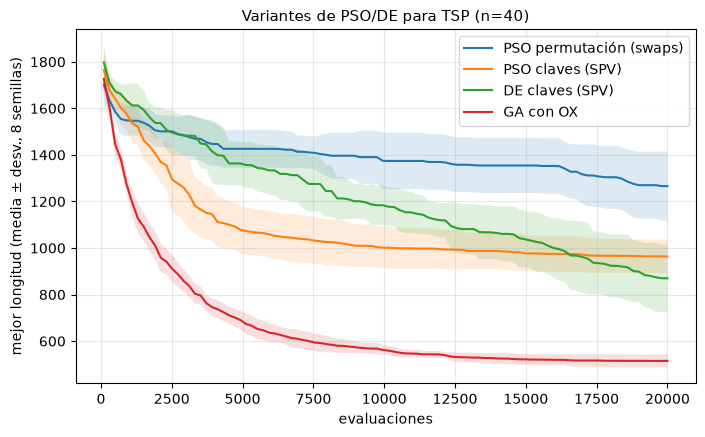

In [22]:
# ---------------- Comparación en TSP n=40: 20000 evaluaciones, 8 semillas ----------------
def batch_tsp(K):
    T = np.argsort(K, axis=1); return dT[T, np.roll(T, -1, axis=1)].sum(axis=1)

def ox_one(p1, p2, rng):
    n = len(p1); a, b = np.sort(rng.choice(n + 1, 2, replace=False)); child = np.full(n, -1); child[a:b] = p1[a:b]
    used = np.zeros(n, bool); used[p1[a:b]] = True; rest = np.roll(p2, -b); rest = rest[~used[rest]]
    child[(np.arange(n - (b - a)) + b) % n] = rest; return child

def ga_ox(d, evals, mu=80, pc=0.9, pm=0.3, k=5, seed=0):
    rng = np.random.default_rng(seed); n = len(d)
    pop = np.argsort(rng.random((mu, n)), axis=1); f = np.array([tour_len(t, d) for t in pop]); ne = mu; ev, best = [ne], [f.min()]
    def inv(t):
        c = t.copy(); i, j = np.sort(rng.choice(n, 2, replace=False)); c[i:j + 1] = c[i:j + 1][::-1]; return c
    while ne < evals:
        cand = rng.integers(0, mu, (mu, k)); pi = cand[np.arange(mu), np.argmin(f[cand], axis=1)]; kids = []
        for i in range(0, mu, 2):
            a, b = pop[pi[i]], pop[pi[i + 1]]
            h1, h2 = (ox_one(a, b, rng), ox_one(b, a, rng)) if rng.random() < pc else (a.copy(), b.copy())
            kids += [inv(h1) if rng.random() < pm else h1, inv(h2) if rng.random() < pm else h2]
        kids = np.array(kids); kf = np.array([tour_len(t, d) for t in kids]); ne += mu
        e, w = np.argmin(f), np.argmax(kf); kids[w], kf[w] = pop[e], f[e]; pop, f = kids, kf; ev.append(ne); best.append(f.min())
    i = f.argmin(); return dict(ev=np.array(ev), best=np.array(best), x=pop[i], f=f[i])

def tarea_tsp(task):
    m, s = task; EV = 20000
    if m == "PSO permutación (swaps)": return task, pso_perm(dT, N=30, evals=EV, seed=s)
    if m == "PSO claves (SPV)":
        r = pso(batch_tsp, 0.0, 1.0, NT, N=40, evals=EV, chi=True, c1=2.05, c2=2.05, seed=s); r["x"] = np.argsort(r["x"]); return task, r
    if m == "DE claves (SPV)":
        r = de(batch_tsp, 0.0, 1.0, NT, NP=60, evals=EV, F=0.5, CR=0.9, seed=s); r["x"] = np.argsort(r["x"]); return task, r
    return task, ga_ox(dT, EV, seed=s)
MT = ["PSO permutación (swaps)", "PSO claves (SPV)", "DE claves (SPV)", "GA con OX"]
t0 = time.time(); out = pmap(tarea_tsp, [(m, s) for m in MT for s in range(8)], procs=12)
RT = {m: [r for (mm, s), r in out if mm == m] for m in MT}; print(f"({time.time()-t0:.0f}s)")
assert all(es_perm(r["x"], NT) and abs(tour_len(r["x"], dT) - r["f"]) < 1e-6 for L in RT.values() for r in L)
print("Todas las soluciones finales son permutaciones válidas con la longitud correcta.")
rand_ref = np.mean([tour_len(rng0.permutation(NT), dT) for _ in range(500)])
print(pd.DataFrame({m: {"media": np.mean([r["f"] for r in L]), "desv.": np.std([r["f"] for r in L], ddof=1), "mejor": min(r["f"] for r in L)} for m, L in RT.items()}).T.round(1))
print("Referencia: tour aleatorio medio =", round(rand_ref, 1), "| mejor 2-opt multi-arranque en esta instancia (notebook 09) ≈ 465")
fig, ax = plt.subplots(figsize=(8, 4.6)); g = np.linspace(100, 20000, 100)
for m, L in RT.items():
    C = np.array([r["best"][np.clip(np.searchsorted(r["ev"], g, side="right") - 1, 0, None)] for r in L]); ax.plot(g, C.mean(0), label=m); ax.fill_between(g, C.mean(0) - C.std(0), C.mean(0) + C.std(0), alpha=0.15)
ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor longitud (media ± desv., 8 semillas)"); ax.set_title("Variantes de PSO/DE para TSP (n=40)"); ax.legend(); plt.show()

**Lectura (a contrastar con la tabla).** Los algoritmos pensados para el espacio continuo (PSO/DE sobre claves SPV) y el PSO con swaps se comparan contra un AG con OX diseñado para permutaciones. Observa dos efectos: (i) la representación importa mucho más que el algoritmo: sobre claves `argsort` el paisaje es rugoso (ver test de localidad del [notebook 10](10-brkga-memeticos-scatter-search.ipynb)); (ii) el PSO de swaps conserva información de adyacencia solo de forma indirecta (un swap rompe 4 aristas, la secuencia de diferencia no está alineada con la geometría del TSP). Ninguna de estas variantes se acerca, sin búsqueda local, a la calidad de los métodos de trayectoria; para TSP se prefieren ACO, AG con operadores de aristas o híbridos con 2-opt.

## Ventajas y limitaciones

| Método | Ventajas | Limitaciones |
|---|---|---|
| **PSO** | muy simple; pocos parámetros; memoria individual; buena convergencia inicial en funciones suaves | sensible a $w,c_1,c_2$ (región de estabilidad); convergencia prematura en *gbest*; no es invariante a rotaciones ni a transformaciones del espacio; versión discreta menos natural |
| **DE** | muy robusto con pocos parámetros ($NP,F,CR$); mutación autoescalada por la dispersión; excelente en continuo, a menudo líder en comparaciones | sensible a $CR$ en funciones separables; estancamiento si la población pierde diversidad; para permutaciones requiere redefiniciones |
| **GA real** | operadores variados; flexible a restricciones y a mezcla de variables | más parámetros; SBX/mutación gaussiana requieren ajuste de escala; suele ser más lento en continuo puro |

## Resumen
- PSO: velocidad con inercia + atracción cognitiva + social; la **región de estabilidad** $|w|<1,\ 0<\varphi<2(1+w)$ (orden 1) y su refinamiento de segundo orden explican por qué ciertas configuraciones divergen aunque "se vean razonables"; la **constricción** formaliza una elección segura.
- DE: mutación por diferencias, cruce binomial, selección voraz; $F$ y $CR$ controlan paso y cuántas coordenadas cambian; `best/1` converge más rápido pero con más riesgo.
- En la comparación por semillas, el ranking depende de la función y la dimensión; **no hay ganador universal**; se reportan medias, desviaciones, medianas y curvas.
- Para permutaciones, PSO se adapta con **secuencias de swaps** (vector diferencial) o con *random keys*, pero no sustituye a operadores diseñados para el problema.

## Ejercicios propuestos
1. Añade a la sección 3 la simulación de un enjambre completo en 1D (con actualización de $p$ y $g$) y estudia empíricamente la región de convergencia.
2. Implementa **inercia decreciente** (0.9→0.4) y compara con constricción en Rastrigin/Ackley 30D.
3. Implementa **DE adaptativo** (jDE o SaDE): $F$ y $CR$ evolucionan por individuo, y compáralo con los valores fijos.
4. Repite el control de rotación con $CR=0.1$ y $CR=1.0$ en DE: ¿cómo cambia su sensibilidad a la rotación? Añade PSO con anillo.
5. Implementa una **topología de von Neumann** (cuadrícula) y compárala con gbest y anillo.
6. Crea un DE de permutaciones con mutación por **diferencias de swaps** y compáralo con el PSO de swaps de la sección 9.

## Referencias
- Kennedy, J., Eberhart, R. (1995). Particle swarm optimization. *Proc. IEEE International Conference on Neural Networks*.
- Shi, Y., Eberhart, R. (1998). A modified particle swarm optimizer. *Proc. IEEE International Conference on Evolutionary Computation*.
- Clerc, M., Kennedy, J. (2002). The particle swarm: explosion, stability, and convergence in a multidimensional complex space. *IEEE Transactions on Evolutionary Computation*, 6(1).
- Poli, R. (2009). Mean and variance of the sampling distribution of particle swarm optimizers during stagnation. *IEEE Transactions on Evolutionary Computation*, 13(4).
- Monson, C. K., Seppi, K. D. (2005). Exposing origin-seeking bias in PSO. *Proc. Genetic and Evolutionary Computation Conference (GECCO)*.
- Kennedy, J., Mendes, R. (2002). Population structure and particle swarm performance. *Proc. Congress on Evolutionary Computation*.
- Clerc, M. (2004). Discrete particle swarm optimization, illustrated by the traveling salesman problem. En *New Optimization Techniques in Engineering*, Springer.
- Storn, R., Price, K. (1997). Differential evolution: a simple and efficient heuristic for global optimization over continuous spaces. *Journal of Global Optimization*, 11.
- Das, S., Suganthan, P. N. (2011). Differential evolution: a survey of the state-of-the-art. *IEEE Transactions on Evolutionary Computation*, 15(1).
- Deb, K., Agrawal, R. B. (1995). Simulated binary crossover for continuous search space. *Complex Systems*, 9.
- Eiben, A. E., Smith, J. E. (2003). *Introduction to Evolutionary Computing*. Springer.